# 06 — Anomalías y alertas estadísticas

Una cifra alta en agosto no significa lo mismo que la misma cifra en febrero. Comparamos cada mes únicamente con los meses del mismo nombre de años anteriores, **dentro de su misma era** (antes de febrero de 2012 el índice es solo MODIS; desde entonces es VIIRS-SNPP solo, a escala MODIS-equivalente: en el parque MODIS casi no ve nada cada mes y mezclarlo añade ruido y dependencia de la calibración sin cambiar apenas las alertas).

Reglas:

- **Modelo de conteos (binomial negativa estacional):** con los años anteriores de la misma era se estima cuántas celdas-día se esperan en cada mes del año, con la variabilidad propia de los conteos de fuego (muchos ceros y años extremos). Con ese modelo se calcula la **probabilidad de exceso**: la probabilidad de ver un mes tan alto o más. Su inverso, el **equivalente en años**, es solo indicativo (sale de un modelo con unos 13 años de datos, no de una frecuencia observada; se muestra hasta 100). Cada mes trae además una **lectura en palabras** (inusual, muy inusual, extremadamente inusual);
- se calcula también el **Z-score clásico** que menciona el reto: (valor − media del mismo mes) / desviación estándar, con un piso de 1 celda-día. Se muestra y se marca `z_score_supera_2`, pero **no decide el nivel**: en una prueba prospectiva un z ≥ 3 ocurrió en el 8,3 % de los meses (debería ser rarísimo), es decir, estaba mal calibrado;
- se muestra también **cuántas veces la mediana histórica** del mismo mes es el valor observado (la comparación simple que pide el reto) y el **percentil histórico**;
- niveles por probabilidad de exceso: `elevada` ≤ 0,10 (vigilancia); `alta` ≤ 0,05 y `muy_alta` ≤ 0,01 (candidatas a verificación);
- **actividad mínima**: el mes debe tener al menos 6 celdas-día de VIIRS (2 de MODIS antes de febrero de 2012; el 6 equivale a 2 celdas-día MODIS-equivalentes con el factor vigente y se fija en conteos para no depender del factor); por debajo no se emite alerta;
- al menos 5 años de historial del mismo mes y era;
- los meses todavía incompletos se marcan `mes_incompleto`.

El baseline es expansivo: para un mes de 2025 solo utiliza años anteriores. Así evitamos usar el futuro para evaluar el pasado.

> Una alerta estadística pide revisión. No confirma por sí sola un incendio y no sustituye FIRMS near-real-time, SERNAP, bomberos ni verificación en campo. Las reglas y umbrales son de prototipo, no criterios oficiales.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
SERIES = ROOT / "DATOS_PROCESADOS" / "series"
FIGURES = ROOT / "DATOS_PROCESADOS" / "figuras"

In [2]:
from pipeline_tunari_avanzado import calcular_alertas

serie = pd.read_csv(SERIES / 'tunari_serie_mensual_armonizada.csv', parse_dates=['mes_bo'])
alertas, destacadas = calcular_alertas(serie)

evaluables = alertas[~alertas['nivel_alerta'].isin(['sin_baseline', 'mes_incompleto'])]
print(f"Meses evaluables: {len(evaluables):,}")
print(f"Meses destacados: {len(destacadas):,} ({100 * len(destacadas) / len(evaluables):.1f} % de los evaluables)")
display(evaluables['nivel_alerta'].value_counts().rename('meses').to_frame())
display(alertas[alertas['anio'].eq(alertas['anio'].max())][
    ['mes_bo','celdas_dia_base','veces_mediana_historica','z_score','probabilidad_exceso','lectura_modelo','nivel_alerta']
])

Meses evaluables: 183
Meses destacados: 16 (8.7 % de los evaluables)


,meses
nivel_alerta,
normal,167
alta,9
elevada,5
muy_alta,2


,mes_bo,celdas_dia_base,veces_mediana_historica,z_score,probabilidad_exceso,lectura_modelo,nivel_alerta
293,2026-01-01,0,NaN,-0.469945,1.000000,Dentro de lo esperable para ese mes,normal
294,2026-02-01,1,NaN,0.857143,0.343497,Dentro de lo esperable para ese mes,normal
295,2026-03-01,0,NaN,-0.285714,1.000000,Dentro de lo esperable para ese mes,normal
296,2026-04-01,2,NaN,1.500000,0.167607,Dentro de lo esperable para ese mes,normal
297,2026-05-01,2,0.666667,-0.416081,0.646721,Dentro de lo esperable para ese mes,normal
298,2026-06-01,14,1.120000,0.011647,0.363845,Dentro de lo esperable para ese mes,normal
299,2026-07-01,30,2.142857,0.354893,0.234723,Dentro de lo esperable para ese mes,normal
300,2026-08-01,39,1.164179,-0.085100,0.364908,Dentro de lo esperable para ese mes,normal
301,2026-09-01,26,1.485714,1.547118,0.177757,Dentro de lo esperable para ese mes,normal
302,2026-10-01,23,1.840000,0.860478,0.159314,Dentro de lo esperable para ese mes,normal


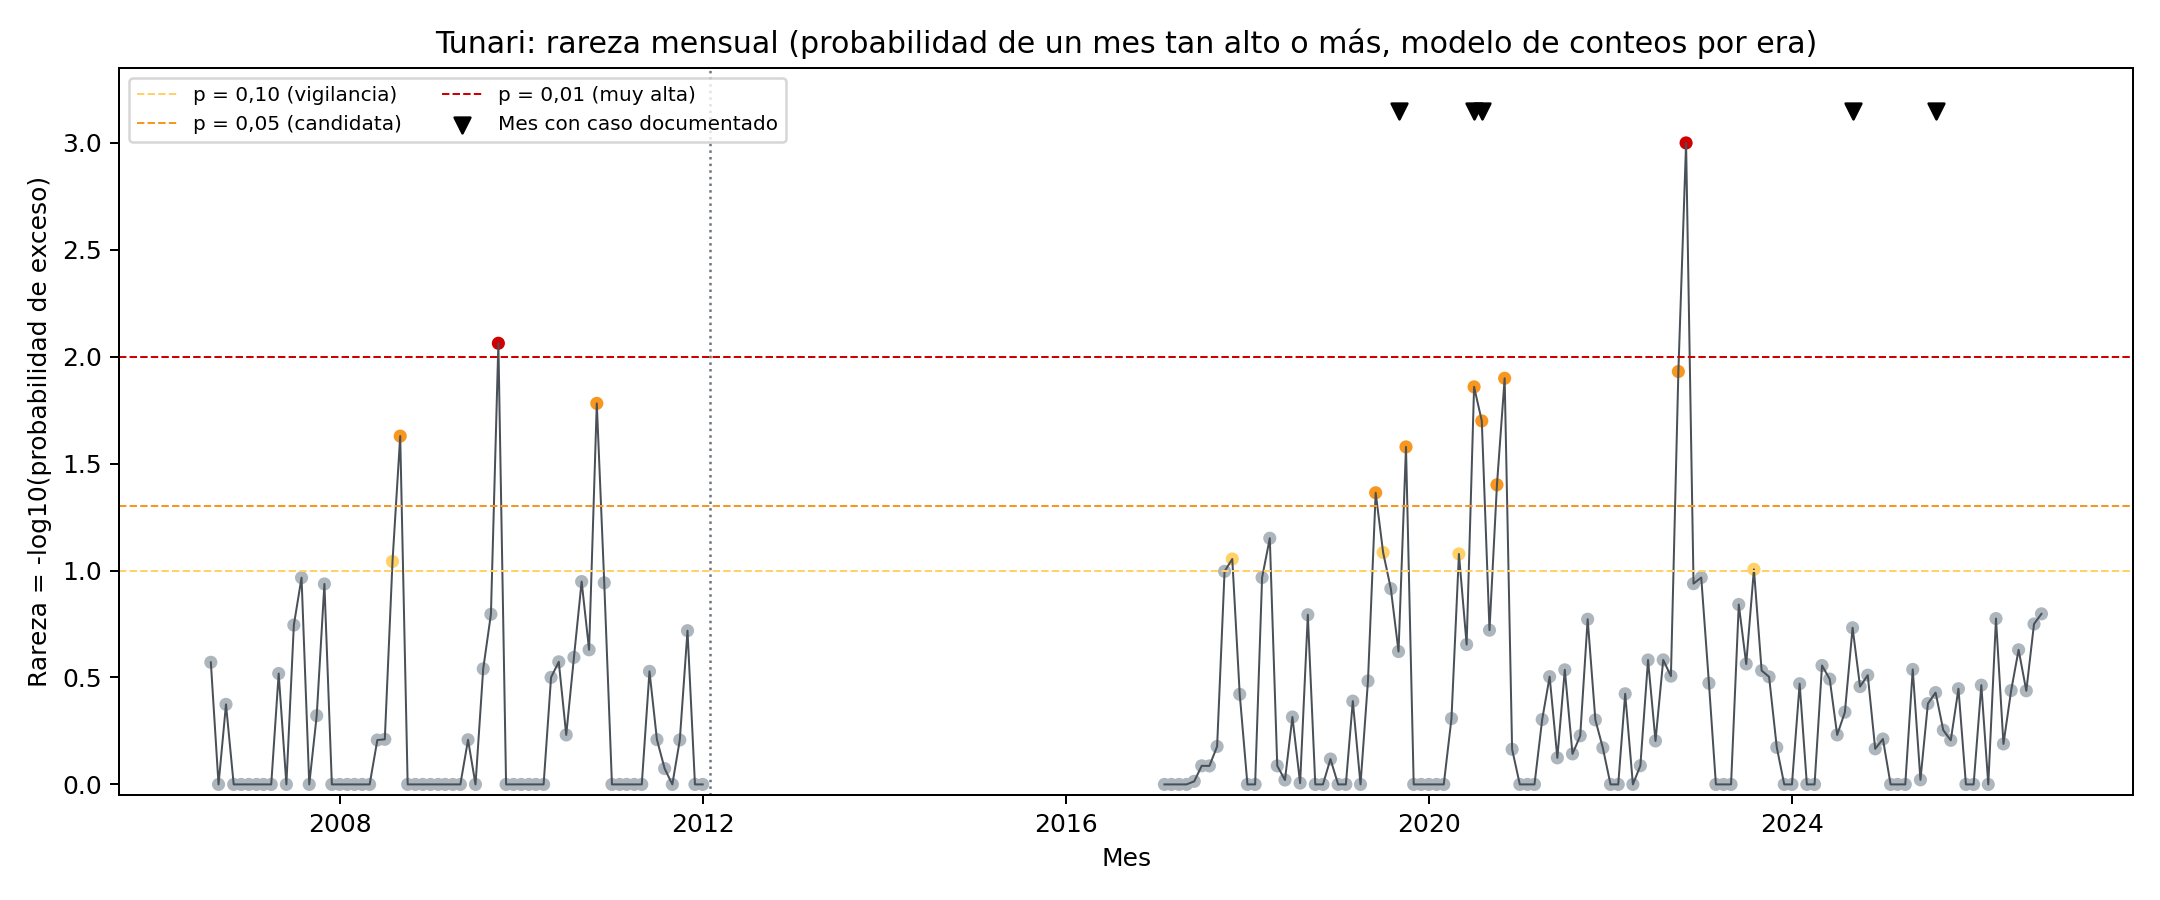

In [3]:
display(Image(filename=str(FIGURES / 'tunari_anomalias_y_alertas.png')))

## ¿Las alertas coinciden con los casos documentados?

Se mira el nivel de alerta del **mes** de cada caso publicado, junto con la tasa general de alertas (la que se esperaría por azar si las alertas no tuvieran relación con los incendios).

In [4]:
casos = pd.read_csv(SERIES / 'tunari_alertas_vs_casos_documentados.csv')
display(casos[['mes_bo','celdas_dia_base','veces_mediana_historica','z_score','probabilidad_exceso','lectura_modelo','nivel_alerta','categoria_alerta','tasa_vigilancia_o_candidata_pct','tasa_candidata_a_verificacion_pct']].round(3))

,mes_bo,celdas_dia_base,veces_mediana_historica,z_score,probabilidad_exceso,lectura_modelo,nivel_alerta,categoria_alerta,tasa_vigilancia_o_candidata_pct,tasa_candidata_a_verificacion_pct
0,2019-09-01,19,1.357,0.566,0.239,Dentro de lo esperable para ese mes,normal,NaN,8.7,6.0
1,2020-07-01,68,6.476,2.184,0.014,Muy inusual: un mes así o más alto ocurre en e...,alta,candidata_a_verificacion,8.7,6.0
2,2020-08-01,107,3.891,2.317,0.020,Muy inusual: un mes así o más alto ocurre en e...,alta,candidata_a_verificacion,8.7,6.0
3,2024-09-01,25,1.429,1.486,0.185,Dentro de lo esperable para ese mes,normal,NaN,8.7,6.0
4,2025-08-01,38,1.267,-0.120,0.372,Dentro de lo esperable para ese mes,normal,NaN,8.7,6.0


Un mes puede quedar en `normal` aunque haya un incendio documentado: el índice es mensual y se compara con meses muy intensos de años anteriores (por ejemplo, agosto de 2025 frente a agosto de 2020). Es una limitación de la escala mensual, no necesariamente un error.

## Dos categorías de uso

- **Vigilancia** (`elevada`): seguimiento, sin movilizar recursos.
- **Candidata a verificación** (`alta` y `muy_alta`): conviene contrastarla con otras fuentes; no es una alerta confirmada ni un criterio institucional.

Los niveles son probabilidades fijadas de antemano (0,10; 0,05; 0,01), no umbrales ajustados a una tasa objetivo. En una prueba prospectiva de 96 meses (2018–2025) con este tipo de modelo, el 9,4 % de los meses cayó en p ≤ 0,10, el 7,3 % en p ≤ 0,05 y el 1,0 % en p ≤ 0,01, cerca de lo nominal pero con incertidumbre amplia (IC 90 %: 3–17 %, 1–15 % y 0–3 %). Las probabilidades son **aproximadas**: el modelo no incorpora la incertidumbre de sus propios parámetros, de modo que el nivel `muy_alta` ocurre en la práctica entre el 1 % y el 3 % de los meses. Los niveles siguen siendo de prototipo.

In [5]:
tabla = evaluables.groupby('categoria_alerta').size().rename('meses').to_frame()
tabla.index = [c if c else 'sin alerta' for c in tabla.index]
tabla['pct_de_evaluables'] = (100 * tabla['meses'] / len(evaluables)).round(1)
display(tabla)

,meses,pct_de_evaluables
sin alerta,167,91.3
candidata_a_verificacion,11,6.0
vigilancia,5,2.7


## Backtest estrictamente prospectivo

El factor operativo VIIRS/MODIS se ajusta con 2013–2025 y se usa para reconstruir todo el historial; en rigor, una alerta de 2017 incorpora así información de años posteriores. Como desde 2012 las alertas usan VIIRS solo, el factor únicamente cambia la escala (la probabilidad de exceso y el percentil no cambian) y afecta solo al umbral de actividad mínima. Para medir cuánto importa, se repite el cálculo de cada año Y con un factor ajustado **solo con años anteriores a Y** (y se reconstruye con ese factor también el historial de referencia).

In [6]:
pros = pd.read_csv(SERIES / 'tunari_alertas_prospectivas.csv')
excluir = ['sin_baseline', 'mes_incompleto', 'sin_ajuste_previo']
comp = pros[pros['era'].eq('MODIS+VIIRS-SNPP') & ~pros['nivel_alerta_prospectivo'].isin(excluir) & ~pros['nivel_alerta_ajuste_final'].isin(excluir[:2])]
marca = ['elevada', 'alta', 'muy_alta']
print(f"Meses comparables (era MODIS+VIIRS): {len(comp)}")
print(f"Mismo nivel con ambos factores: {100 * (comp['nivel_alerta_prospectivo'] == comp['nivel_alerta_ajuste_final']).mean():.1f} %")
print(f"Mismo resultado alerta sí/no: {100 * (comp['nivel_alerta_prospectivo'].isin(marca) == comp['nivel_alerta_ajuste_final'].isin(marca)).mean():.1f} %")
display(pd.crosstab(comp['nivel_alerta_ajuste_final'], comp['nivel_alerta_prospectivo']))
display(comp[comp['nivel_alerta_prospectivo'] != comp['nivel_alerta_ajuste_final']][['mes_bo', 'nivel_alerta_ajuste_final', 'nivel_alerta_prospectivo', 'periodo_ajuste_factor']])

Meses comparables (era MODIS+VIIRS): 117
Mismo nivel con ambos factores: 100.0 %
Mismo resultado alerta sí/no: 100.0 %


nivel_alerta_prospectivo,alta,elevada,muy_alta,normal
nivel_alerta_ajuste_final,,,,
alta,7,0,0,0
elevada,0,4,0,0
muy_alta,0,0,1,0
normal,0,0,0,105


,mes_bo,nivel_alerta_ajuste_final,nivel_alerta_prospectivo,periodo_ajuste_factor


Si ambos coinciden casi siempre, la fuga temporal es pequeña en la práctica. El factor ajustado con 2013–2025 es el válido para operar desde 2026 en adelante.

## ¿Mejora el modelo si se le agrega el clima?

Se probó con datos de ERA5 en un punto del parque (`explorar_clima_anomalias.py`). El balance hídrico de 3 meses (lluvia menos evapotranspiración) baja el CRPS un 14 % y 11 de los 12 meses en alerta desde 2013 fueron más secos de lo normal. **No se integró al pipeline**: es una dependencia externa y un solo punto de ERA5 para un parque de gran desnivel.

## Qué haría falta para una alerta operativa real

1. Actualizar diariamente con FIRMS NRT.
2. Incorporar pasadas sin detección, nubosidad y calidad de observación.
3. Usar el límite oficial y perímetros de incendios confirmados.
4. Definir responsables y protocolo de verificación antes de comunicar una alerta.
5. Recalibrar cuando cambien sensores o versiones de procesamiento.